In [1]:
import torch
import numpy as np

# PyTorch基础目录:
1. [张量的创建](#1-张量的创建)
2. [数据类型及其转换](#2-数据类型及其转换)
3. [张量与NumPy数组的转换](#3-张量与NumPy数组的转换)
4. [张量基本运算](#4-张量基本运算)
5. [张量函数运算](#5-张量函数运算)
6. [张量索引与切片](#6-张量索引与切片)
7. [张量的形状操作](#7-张量的形状操作)
8. [张量的拼接操作](#8-张量的拼接操作)
9. [自动微分机制](#9-自动微分机制)
10. [线性回归例子](#10-线性回归例子)

# 1. 张量的创建
### 基本张量
- `torch.tensor(data, dtype=None)`: 根据传入的数据创建张量
- `torch.Tensor(*sizes)`: 根据传入的形状创建张量
- `torch.from_numpy(ndarray)`: 根据传入的numpy数组创建张量, 创建的张量和numpy数组共享内存
- `tensor.shape`: 张量的形状
### 常数张量
- `torch.zeros(*sizes)`: 创建一个全为0的张量
    - `torch.zeros_like(input)`: 创建一个和输入张量形状相同的全为0的张量
- `torch.ones(*sizes)`: 创建一个全为1的张量
    - `torch.ones_like(input)`: 创建一个和输入张量形状相同的全为1的张量
- `torch.full(*sizes, fill_value)`: 创建一个全为指定值的张量
    - `torch.full_like(input, fill_value)`: 创建一个和输入张量形状相同的全为指定值的张量
### 线性和随机张量
- `torch.arange(start, end, step)`: 创建一个指定范围的张量
- `torch.linspace(start, end, steps)`: 创建一个线性间隔的张量 (等差数列)
- `torch.rand(*sizes)`: 创建一个指定形状的均匀分布的随机张量 (范围在`[0, 1)`之间)
- `torch.randn(*sizes)`: 创建一个指定形状的标准正态分布的随机张量 (均值为0，标准差为1)
- `torch.randint(low, high, size)`: 创建一个指定范围的随机整数张量
- `torch.random.initial_seed()`: 获取当前随机数种子. 默认采用当前系统的时间戳作为随机数种子
- `torch.manual_seed(seed)`: 设置随机数种子. 确定种子后, 每次运行代码生成的随机数都是相同的

基本张量

In [2]:
# 1. 根据传入的数据创建张量
t1 = torch.tensor([[1, 2], [3, 4]])
# 指定数据类型
# 使用最多的数据类型是float32, 其次int64
t2 = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
# 传入numpy数组创建张量
t3 = torch.tensor(np.array([[1, 2], [3, 4]]))
t3 = torch.from_numpy(np.array([[1, 2], [3, 4]])) # from_numpy创建的张量和numpy数组共享内存 (修改张量会影响numpy数组，反之亦然)

# 2. 根据传入的形状创建张量
t3 = torch.Tensor(2, 3) # 创建一个2行3列的张量
# 也支持传递numpy的ndarray
t4 = torch.Tensor(np.array([[1, 2], [3, 4]]))

t1, t2, t3, t4, t1.shape

(tensor([[1, 2],
         [3, 4]]),
 tensor([[1., 2.],
         [3., 4.]]),
 tensor([[0., 0., 0.],
         [0., 0., 0.]]),
 tensor([[1., 2.],
         [3., 4.]]),
 torch.Size([2, 2]))

常数张量


In [3]:
# 1. 创建一个全为0的张量
t1 = torch.zeros(2, 3)
# 创建一个和输入张量形状相同的全为0的张量
t2 = torch.zeros_like(t1)
# 2. 创建一个全为1的张量
t3 = torch.ones(2, 3)
# 创建一个和输入张量形状相同的全为1的张量
t4 = torch.ones_like(t3)
# 3. 创建一个全为指定值的张量
t5 = torch.full((255, 255), 5)
# 创建一个和输入张量形状相同的全为指定值的张量
t5 = torch.full_like(t5, 7)
print(f"t1: {t1}\nt2: {t2}\nt3: {t3}\nt4: {t4}\nt5: {t5}")

t1: tensor([[0., 0., 0.],
        [0., 0., 0.]])
t2: tensor([[0., 0., 0.],
        [0., 0., 0.]])
t3: tensor([[1., 1., 1.],
        [1., 1., 1.]])
t4: tensor([[1., 1., 1.],
        [1., 1., 1.]])
t5: tensor([[7, 7, 7,  ..., 7, 7, 7],
        [7, 7, 7,  ..., 7, 7, 7],
        [7, 7, 7,  ..., 7, 7, 7],
        ...,
        [7, 7, 7,  ..., 7, 7, 7],
        [7, 7, 7,  ..., 7, 7, 7],
        [7, 7, 7,  ..., 7, 7, 7]])


线性和随机张量

In [4]:
# 1. 创建一个指定范围的张量
t1 = torch.arange(0, 10, 2) # [0, 2, 4, 6, 8]
t2 = torch.linspace(0, 1, 5) # [0, 0.25, 0.5, 0.75, 1]
# 2. 创建一个指定形状的均匀分布的随机张量
t3 = torch.rand(2, 3) # 2行3列的均匀分布随机张量
# 3. 创建一个指定形状的标准正态分布的随机张量
t4 = torch.randn(2, 3) # 2行3列的标准正态分布随机张量
# 4. 创建一个指定范围的随机整数张量
t5 = torch.randint(0, 10, (2, 3)) # 2行3列的随机整数张量，范围在[0, 10)之间
# 5. 获取当前随机数种子
seed = torch.random.initial_seed()
print(f"t1: {t1}\nt2: {t2}\nt3: {t3}\nt4: {t4}\nt5: {t5}\nseed: {seed}")
# 设置随机数种子
torch.manual_seed(123456)
print(f'seed: {torch.random.initial_seed()}')

t1: tensor([0, 2, 4, 6, 8])
t2: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
t3: tensor([[0.6686, 0.0404, 0.2418],
        [0.4096, 0.2473, 0.6439]])
t4: tensor([[ 0.1833, -0.5639, -1.4351],
        [-0.2621,  0.1991,  0.8940]])
t5: tensor([[8, 4, 8],
        [9, 3, 9]])
seed: 440332161837900
seed: 123456


# 2. 数据类型及其转换
- torch数据类型包括:
    | 数据类型 `dtype` | 说明 |
    | --- | --- |
    | torch.float32 | 32位浮点数 **(浮点数默认类型)** |
    | torch.float64 | 64位浮点数 |
    | torch.float16 | 16位浮点数 |
    | torch.int8 | 8位整数 |
    | torch.int16 | 16位整数 |
    | torch.int32 | 32位整数 |
    | torch.int64 | 64位整数 **(整数默认类型)** |
    | torch.uint8 | 8位无符号整数 |
    | torch.bool | 布尔类型 |
- 张量的数据类型通过张量的`dtype`属性获取
- 张量的数据类型可以通过`tensor.to(dtype)`或者`tensor.type(dtype)`方法进行转换

In [5]:
t = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)
# 1. 获取张量的数据类型
print(f"t.dtype: {t.dtype}, t.type(): {type(t)}")

# 2. 转换张量的数据类型
t1 = t.to(torch.int32) # 使用to方法转换数据类型
t1 = t.type(torch.int32) # 使用type方法转换数据类型
print(t1)

t2 = t.to(torch.float64)
print(t2)

t3 = t.type(torch.bool)
print(t3)

t.dtype: torch.float32, t.type(): <class 'torch.Tensor'>
tensor([[1, 2, 3],
        [4, 5, 6]], dtype=torch.int32)
tensor([[1., 2., 3.],
        [4., 5., 6.]], dtype=torch.float64)
tensor([[True, True, True],
        [True, True, True]])


# 3. 张量与NumPy数组的转换
- Numpy数组 -> 张量
    - `torch.from_numpy(ndarray)`: 创建的张量**和NumPy数组共享内存**, 修改张量会影响NumPy数组, 反之亦然.
    - `torch.tensor(data, dtype=None)`: 创建的张量**和NumPy数组不共享内存**
- 张量 -> Numpy数组
    - `tensor.numpy()`: 将张量转换为NumPy数组, 创建的NumPy**数组和张量共享内存**
- 当张量中只有一个元素时, 可以使用`tensor.item()`方法将张量转换为Python的标量类型

In [6]:
# 1. Numpy数组 -> 张量
t = torch.tensor([[1, 2, 3], [4, 5, 6]])
arr = np.array([[1, 2, 3], [4, 5, 6]])
t1 = torch.from_numpy(arr) # 共享内存
# 使用ndarray.copy()方法创建的张量和NumPy数组不共享内存
t1 = torch.tensor(arr.copy()) # 不共享内存

# 2. 张量 -> Numpy数组
arr1 = t.numpy() # 共享内存
# 不想共享的话copy()一份
arr1 = t.numpy().copy()

# 3. 单个元素张量 -> Python标量
print(torch.tensor(1).item()) # ==> 1
print(torch.tensor([True]).item()) # ==> True
print(torch.tensor([[[[1,],]],]).item()) # ==> 1

1
True
1


# 4. 张量基本运算
- 加减乘除, 取反: `add`, `sub`, `mul`, `div`, `neg`
    - 这些方法后面都可以加上`_`表示原地操作: `add_`, `sub_`, `mul_`, `div_`, `neg_`
    > 例如: `t = t.add(1) <=> t = t + 1 <=> t += 1 <=> t.add_(1)`
    - 也可以用符号: `+ - * / ~`
- 点乘: `torch.mul(t1, t2) 或者 t1 * t2`
- 矩阵乘法: `torch.matmul(t1, t2) 或者 t1 @ t2`, 其中t1.shape=`[m ,n]`, t2.shape=`[n, k]`

In [7]:
# 基本运算
t1 = torch.tensor([[1, 2], [3, 4]])
t2 = torch.tensor([[2, 3], [4, 5]])

print(f't1 + 2: \n{t1 + 2}')
print(f't1 - 2: \n{t1 - 2}')
print(f't1 * 2: \n{t1 * 2}')
print(f't1 / 2: \n{t1 / 2}')
print(f'~t1: \n{~t1}')

# 点乘
print(f'dot: {torch.mul(t1, t2)}')
# 矩阵乘法
print(f'matmul: {torch.matmul(t1, t2)}')

t1 + 2: 
tensor([[3, 4],
        [5, 6]])
t1 - 2: 
tensor([[-1,  0],
        [ 1,  2]])
t1 * 2: 
tensor([[2, 4],
        [6, 8]])
t1 / 2: 
tensor([[0.5000, 1.0000],
        [1.5000, 2.0000]])
~t1: 
tensor([[-2, -3],
        [-4, -5]])
dot: tensor([[ 2,  6],
        [12, 20]])
matmul: tensor([[10, 13],
        [22, 29]])


# 5. 张量函数运算
- `sum(tensor, dim=None, keepdim=False)`: 对张量指定维度求和
    - `dim`: 指定求和的维度, 如果为None, 则对所有元素求和
    - `keepdim`: 是否保留求和后的维度, 默认为False
- `mean(tensor, dim=None, keepdim=False)`: 对张量指定维度求平均值
- `max(tensor, dim=None, keepdim=False)`: 对张量指定维度求最大值
- `min(tensor, dim=None, keepdim=False)`: 对张量指定维度求最小值
- `argmax(tensor, dim=None, keepdim=False)`: 对张量指定维度求最大值的索引
- `sqrt(tensor)`: 对张量的每个元素求平方根
- `exp(tensor)`: 对张量的每个元素求指数
- `log(tensor)`: 对张量的每个元素求自然对数(e为底)
- `log2(tensor)`: 对张量的每个元素求以2为底的对数
- `log10(tensor)`: 对张量的每个元素求以10为底的对数
- `abs(tensor)`: 对张量的每个元素求绝对值
- `pow(tensor, exponent)`: 对张量的每个元素求幂

这些函数都可以使用`torch.`前缀调用(静态方法), 也可以使用张量对象调用, 例如: `t.sum(dim=0)` 等价于 `torch.sum(t, dim=0)`

In [8]:
# 张量函数运算
torch.manual_seed(123456)
t = torch.randint(0, 10, (3, 4))
print(f"t: \n{t}")

print(f"torch.sum(t): {torch.sum(t)}")
print(f"torch.sum(t, dim=0): {t.sum(dim=0)}")
print(f"torch.sum(t, dim=1, keepdim=True): {torch.sum(t, dim=1, keepdim=True)}")

print(f'exponent: {torch.exp(t)}')

t: 
tensor([[5, 4, 0, 3],
        [8, 7, 9, 7],
        [7, 4, 9, 6]])
torch.sum(t): 69
torch.sum(t, dim=0): tensor([20, 15, 18, 16])
torch.sum(t, dim=1, keepdim=True): tensor([[12],
        [31],
        [26]])
exponent: tensor([[1.4841e+02, 5.4598e+01, 1.0000e+00, 2.0086e+01],
        [2.9810e+03, 1.0966e+03, 8.1031e+03, 1.0966e+03],
        [1.0966e+03, 5.4598e+01, 8.1031e+03, 4.0343e+02]])


# 6. 张量索引与切片
张量的索引和切片与numpy数组类似, 支持整数索引, 切片索引, 布尔索引, 高级索引等

张量的索引和切片返回的是张量的视图(view), 修改视图会影响原张量, 反之亦然

- 其中的高级索引是指使用整数数组或布尔数组进行索引
    > 例如: `t[[0, 1], [1, 2]]` 表示获取第0行第1列和第1行第2列的元素, 共2个元素
    >
    > `t[t > 0]` 表示获取所有大于0的元素, 返回的是一个一维张量
    >
    > `t[[[0], [1]], [1, 2]]` 获取第0, 1行的第1, 2列的共4个元素, 返回的是二维张量. (因为行索引是二维的(2, 1), 列索引是一维的(2,), 它们会先进行广播, 然后再进行索引)
- 切片索引中三个量的含义: `[start:stop:step]`, 其中`start`表示起始索引, `stop`表示结束索引(不包含), `step`表示步长, 默认为1

In [9]:
t = torch.arange(0, 25).reshape(5, 5)
print(t)
"""
tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [15, 16, 17, 18, 19],
        [20, 21, 22, 23, 24]])
"""

# 1. 整数索引
print(f"t[0]: \n{t[0]}") # 获取第一行
print(f"t[:, 0]: \n{t[:, 0]}") # 获取第一列
print(f"t[0, 0]: \n{t[0, 0]}") # 获取第一个元素
print(f't[[0, 0], [1, 1]]: \n{t[[0, 1], [0, 1]]}') # 获取第一个元素和第二行第二列的元素
print(f't[[[0], [1]], [1, 2]]: \n{t[[[0], [1]], [1, 2]]}') # 获取第0, 1行的第1, 2列的共4个元素. 发现行索引是(2, 1), 列索引是(2,), 会先进行广播再索引, 得到二维张量
print(f't[t > 10]: \n{t[t > 10]}') # 获取所有大于10的元素
print(f'[t > 10]: \n{[t > 10]}') # 获取所有大于10的元素, 返回的是一个布尔张量, 其中True表示对应的元素大于10, False表示对应的元素小于等于10
print(t[1::2, 0::2]) # 返回所有奇数行和偶数列的元素(注意索引从0开始)

tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [15, 16, 17, 18, 19],
        [20, 21, 22, 23, 24]])
t[0]: 
tensor([0, 1, 2, 3, 4])
t[:, 0]: 
tensor([ 0,  5, 10, 15, 20])
t[0, 0]: 
0
t[[0, 0], [1, 1]]: 
tensor([0, 6])
t[[[0], [1]], [1, 2]]: 
tensor([[1, 2],
        [6, 7]])
t[t > 10]: 
tensor([11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24])
[t > 10]: 
[tensor([[False, False, False, False, False],
        [False, False, False, False, False],
        [False,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True]])]
tensor([[ 5,  7,  9],
        [15, 17, 19]])


# 7. 张量的形状操作
- `tensor.reshape(*sizes)`: 改变张量的形状, 返回一个新的张量, 原张量不变
    - `*sizes=a, b, c, ...` 要满足 `a * b * c * ... = tensor.numel()`, 其中`tensor.numel()`表示张量的元素个数
- `tensor.squeeze(dim=None)`: 去掉张量中大小为1的维度, 返回一个新的张量, 原张量不变
    - `dim`: 指定去掉的维度, 如果该维度的大小不为1, 则不会去掉该维度. None表示去掉所有大小为1的维度
- `tensor.unsqueeze(dim)`: 在张量中指定的一个维度上增加一个维度, 返回一个新的张量, 原张量不变
- `tensor.transpose(*dims)`: 交换张量的两个维度, 返回一个新的张量, 原张量不变. 在二维张量即矩阵中等价于转置操作
    - `tensor.T`: 转置张量, 等价于`tensor.transpose(0, 1)` (矩阵转置)
- `tensor.permute(*dims)`: 重新排列张量的维度, 返回一个新的张量, 原张量不变
- 张量的连续性: 表示一个张量的逻辑内容和物理存储在内存中的布局是否一致
    > 比如, 一个刚创建张量的形状为`(2, 3)`, 其逻辑内容为`[[1, 2, 3], [4, 5, 6]]`, 其物理存储在内存中的布局为`[1, 2, 3, 4, 5, 6]`, 则该张量是连续的. 如果对该张量进行转置操作, 则其逻辑内容为`[[1, 4], [2, 5], [3, 6]]`, 但是其物理存储在内存中的布局仍然为`[1, 2, 3, 4, 5, 6]`, 则该张量是**不连续**的.
    - `tensor.is_contiguous()`: 判断张量是否连续, 返回一个布尔值
    - `tensor.contiguous()`: 将不连续的张量转换为连续的张量, 返回一个新的张量, 原张量不变
- `tensor.view(*sizes)`: 改变张量的形状, 返回一个新的张量, 原张量不变. 该方法要求张量是连续的, 否则会报错. 如果张量是不连续的, 可以先转化为连续张量再view:使用`tensor.contiguous().view(*sizes)`
    - `tensor.reshape(*sizes)`底层会自动判断张量是否连续, 如果不连续会先转化为连续的, 相当于:`tensor.contiguous().view(*sizes)`, 如果连续则直接使用`tensor.view(*sizes)`, **所以推荐使用`tensor.reshape(*sizes)`方法**

In [10]:
# 12个元素的数组
t = torch.arange(0, 12)
print(f't.shape: {t.shape}')

# 重组为(3, 2, 2)的张量
t = t.reshape(3, 2, 2)
print(f't.shape: {t.shape}')

print('t = \n', t)
print('='*30)
# 画成3维立方的样子就好理解了
print('t.transpose(0, 1)) = \n', t.transpose(0, 1)) # 交换第0维和第1维
print('t.permute(1, 2, 0) = \n', t.permute(1, 2, 0)) # 重新排列维度为(1, 2, 0)


t.shape: torch.Size([12])
t.shape: torch.Size([3, 2, 2])
t = 
 tensor([[[ 0,  1],
         [ 2,  3]],

        [[ 4,  5],
         [ 6,  7]],

        [[ 8,  9],
         [10, 11]]])
t.transpose(0, 1)) = 
 tensor([[[ 0,  1],
         [ 4,  5],
         [ 8,  9]],

        [[ 2,  3],
         [ 6,  7],
         [10, 11]]])
t.permute(1, 2, 0) = 
 tensor([[[ 0,  4,  8],
         [ 1,  5,  9]],

        [[ 2,  6, 10],
         [ 3,  7, 11]]])


In [11]:
deepList = t.reshape(1, 1, -1)
print(deepList)
# 删除所有大小为1的维度
squeeze = deepList.squeeze()
print(squeeze)
# unsqueeze在指定维度上增加一个维度, 长度为1. 可以传递负数, 表示从最后一个维度开始数, 但也不能越界shape
print(t.shape) # [3, 2, 2]
print(t.unsqueeze(0).shape) # [1, 3, 2, 2]
print(t.unsqueeze(1).shape) # [3, 1, 2, 2]
print(t.unsqueeze(-2).shape) # [3, 2, 1, 2]

tensor([[[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]]])
tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
torch.Size([3, 2, 2])
torch.Size([1, 3, 2, 2])
torch.Size([3, 1, 2, 2])
torch.Size([3, 2, 1, 2])


In [12]:
t = torch.arange(0, 6).view(2, 3) # view要求张量是连续的
print(t)

tTrans = t.transpose(0, 1) # 转置后的张量是不连续的
print(tTrans.is_contiguous()) # False

# tTrans.view(1, 6) # 报错, 因为tTrans是不连续的

print(tTrans.contiguous().view(1, 6)) # 先转化为连续的再view, 不报错
print(tTrans.reshape(1, 6)) # reshape底层会自动判断张量是否连续, 如果不连续会先转化为连续的, 不报错
# 📌所以一般推荐使用reshape方法, 因为它更安全, 不需要考虑张量是否连续

tensor([[0, 1, 2],
        [3, 4, 5]])
False
tensor([[0, 3, 1, 4, 2, 5]])
tensor([[0, 3, 1, 4, 2, 5]])


# 8. 张量的拼接操作
- `torch.cat(tensors, dim=0)`: 将多个张量沿着它们已有的维度拼接, 返回一个新的张量, 原张量不变
    - `tensors`: 要拼接的张量序列, 可以是列表或元组
    - `dim`: 指定拼接的维度, 默认为0
- `torch.stack(tensors, dim=0)`: 在一个新的维度上堆叠多个张量, 返回一个新的张量**(维度数增加)**, 原张量不变
    - `tensors`: 要堆叠的张量序列, 可以是列表或元组
    - `dim`: 指定堆叠的维度, 默认为0
    - `torch.stack()`相当于先对每个张量使用`unsqueeze(dim)`增加一个维度, 然后再沿着这个新的维度进行`torch.cat()`拼接

In [13]:
# 1. torch.cat()拼接张量
t1 = torch.arange(0, 6).reshape(2, 3)
t2 = torch.arange(6, 12).reshape(2, 3)
print(f't1: \n{t1}\nt2: \n{t2}')
# 沿着第0维拼接
t3 = torch.cat((t1, t2), dim=0)
print(f't3: \n{t3}')

# 2. torch.stack()堆叠张量
t3 = torch.stack((t1, t2), dim=2)
# 相当于unsqueeze(dim=2)之后再沿着这个新的维度dim=2进行cat拼接, 所以t3的形状为(2, 3, 2)
print(f't3: \n{t3}, shape: {t3.shape}')

t1: 
tensor([[0, 1, 2],
        [3, 4, 5]])
t2: 
tensor([[ 6,  7,  8],
        [ 9, 10, 11]])
t3: 
tensor([[ 0,  1,  2],
        [ 3,  4,  5],
        [ 6,  7,  8],
        [ 9, 10, 11]])
t3: 
tensor([[[ 0,  6],
         [ 1,  7],
         [ 2,  8]],

        [[ 3,  9],
         [ 4, 10],
         [ 5, 11]]]), shape: torch.Size([2, 3, 2])


# 9. 自动微分机制
- `torch.tensor(data, requires_grad=False)`: 创建一个张量, 如果`requires_grad=True`, 则该张量会记录对它的操作, 以便进行反向传播计算梯度(导数)
- `tensor.backward()`: 对张量进行反向传播, 计算梯度(导数). 即进行$\frac{\partial y}{\partial x}$的计算, 其中$y$是标量张量, $x$是需要计算梯度的张量
- `tensor.grad`: 获取计算出的张量梯度(导数)值

注意: **PyTorch只能对标量(0维张量)进行反向传播**, 如果是非标量张量(包含多个数字), 需要将其转化为标量张量后才可进行反向传播. 可以用`tensor.sum()`或者`tensor.mean()`
- 即: $y = WX + b$ 中, $y$ 必须得是标量才能进行反向传播.

### 更新参数
- `torch.no_grad()`: 上下文管理器, 在该上下文中, 所有计算都不会被记录到计算图中, 也就不会计算梯度(导数)

In [14]:
# 简单的自动微分例子

# 1. 创建一个标量张量, 并设置requires_grad=True, 表示需要计算梯度
w = torch.tensor(10.0, requires_grad=True)

# 2. 定义一个关于w的函数, 比如损失函数
loss = 2 * torch.pow(w, 2) # 损失函数为loss = 2 * w ^ 2
# 查看梯度函数类型
print(f'loss.grad_fn: {type(loss.grad_fn)}') # <MulBackward0>

# 3. 计算梯度, 即损失函数对w的导数
loss.backward() # 计算梯度, 即dloss/dw

# 4. 用计算出的梯度值, 即dloss/dw = 4 * w = 40更新w
print(f'计算出的梯度: {w.grad}') # 40.0
assert w.grad is not None, "梯度计算失败, w.grad为None"

# 在更新w的值时, 不需要计算梯度, 所以使用torch.no_grad()上下文管理器
# 否则w = w - 0.01 * w.grad会被记录到计算图中, 导致w的后续梯度计算错误
with torch.no_grad():
    w = w - 0.01 * w.grad # 更新w的值, 学习率为0.01

print(f'更新后的w: {w}') # 9.6

loss.grad_fn: <class 'MulBackward0'>
计算出的梯度: 40.0
更新后的w: 9.600000381469727


### 循环更新参数
上面的例子只更新了一次参数. 这个例子中循环更新参数, 直到找到极小点和极小值或其近似.
- 在循环中需要使用 `x.grad.zero_()` 将梯度清零, 因为PyTorch默认会累加梯度
- 更新参数时, 如果直接 `x = x - alpha * x.grad`, 会导致 `x` 被等号右边新的张量覆盖, 其梯度 `grad` 就没有了, 清零时会报错. 应该用 `x -= alpha * x.grad` 来更新参数, 因为 `x` 是一个**张量对象**, 对 `-=` 操作符进行了重载, 会在**原地更新** `x` 的值, 从程序上说与第一种方法**不等价**

In [15]:
# 初始化变量x, 设初始x=10, 也可以随机初始化
x = torch.tensor(10.0, requires_grad=True)
# 要求极小值的函数为y = 2x^2 + 3x + 5
def f(x: torch.Tensor) -> torch.Tensor:
    return 2 * torch.pow(x, 2) + 3 * x + 5

# 学习率
alpha = 0.01
# 迭代次数
num_epochs = 1000
for epoch in range(num_epochs):
    # 1. 前向传播, 计算损失函数值
    loss: torch.Tensor = f(x)
    # 2. 反向传播, 计算梯度
    # 每次训练的样本大于1个时, loss就是一个向量而不是标量, 得求和或求平均值
    loss.mean().backward()
    # 3. 更新参数
    with torch.no_grad():
        # 原地更新x的值, 避免x被等号右边新的没有梯度的张量覆盖
        # x是一个重载了-=操作符的张量📌对象📌. 这在数值上等价于 x = x - alpha * x.grad, 但是后者会将x替换为新的没有梯度的张量.
        x -= alpha * x.grad
    if epoch % 10 == 0:
        print(f'第{epoch}次迭代 | x: {x} | loss: {loss} | grad: {x.grad}')
    # 4. 梯度清零.
    x.grad.zero_()

print(f'极小值点: {x}, 极小值: {f(x)}') # x_min = -0.75, f(x_min) = 3.875

第0次迭代 | x: 9.569999694824219 | loss: 235.0 | grad: 43.0
第10次迭代 | x: 6.111072063446045 | loss: 106.03279113769531 | grad: 28.587800979614258
第20次迭代 | x: 3.811464786529541 | loss: 49.028995513916016 | grad: 19.006103515625
第30次迭代 | x: 2.2826106548309326 | loss: 23.833175659179688 | grad: 12.63587760925293
第40次迭代 | x: 1.2661786079406738 | loss: 12.696563720703125 | grad: 8.400744438171387
第50次迭代 | x: 0.5904214382171631 | loss: 7.774152755737305 | grad: 5.585089683532715
第60次迭代 | x: 0.1411559283733368 | loss: 5.598434925079346 | grad: 3.7131495475769043
第70次迭代 | x: -0.15753045678138733 | loss: 4.636762619018555 | grad: 2.468623161315918
第80次迭代 | x: -0.35610687732696533 | loss: 4.211700916290283 | grad: 1.641221284866333
第90次迭代 | x: -0.4881269633769989 | loss: 4.023822784423828 | grad: 1.0911376476287842
第100次迭代 | x: -0.575898289680481 | loss: 3.9407799243927 | grad: 0.7254238128662109
第110次迭代 | x: -0.6342514753341675 | loss: 3.9040749073028564 | grad: 0.4822854995727539
第120次迭代 | x: -0.673

#### `detach()` 分离得到CPU张量

In [16]:
# 得到的张量没法直接转为NumPy数组, 因为需要计算梯度.
# 用detach()方法将张量从计算图中分离(detach)出来, 这样就可以转为NumPy数组了
# 这样得到的torch张量与原来的张量共享内存
print(x)          # tensor(-0.7500, requires_grad=True)
print(x.detach()) # tensor(-0.7500)

arr = x.detach().numpy() # 转为NumPy数组, 共享内存
print(arr) # -0.75
arr.fill(3) # 修改NumPy数组的值, 会影响原来的张量
print(arr) # 3.0
print(x) # tensor(3., requires_grad=True)

tensor(-0.7500, requires_grad=True)
tensor(-0.7500)
-0.7499993
3.0
tensor(3., requires_grad=True)


### 多个参数的批量梯度下降
下面的例子实际上相当于一个神经网络层, 输入5个特征, 输出3个特征.

In [17]:
# 输入的训练集: 2个样本, 5个特征
x = torch.ones(2, 5)
# 目标值: 3个特征
y = torch.ones(2, 3)
# 权重矩阵: 5个输入特征, 3个输出特征
# 别忘了开启梯度计算
w = torch.randn(5, 3, requires_grad=True)
b = torch.randn(3, requires_grad=True)

# 前向预测, 得到网络输出值
def forward(x: torch.Tensor) -> torch.Tensor:
    return x @ w + b # 矩阵乘法, 也可以用torch.matmul(x, w)代替x @ w

# 定义损失函数, 这里使用均方误差(MSE)损失函数
# def func_MSE(y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
#     return torch.mean(torch.pow((y_pred - y_true), 2))
# 直接调用torch的内置函数
func_MSE = torch.nn.MSELoss()

print(f'loss: {loss}, w.grad: {w.grad}, b.grad: {b.grad}')

alpha = 0.01 # 学习率
num_epochs = 1000 # 迭代次数
for epoch in range(num_epochs):
    # 前向传播, 计算损失函数值
    loss = func_MSE(forward(x), y)
    # 反向传播, 计算梯度
    loss.backward()

    # 更新参数
    with torch.no_grad():
        w -= alpha * w.grad
        b -= alpha * b.grad
    if epoch % 100 == 0:
        print(f'第{epoch}次迭代 | loss: {loss}, w.grad: {w.grad}, b.grad: {b.grad}')
    # 梯度清零
    w.grad.zero_()
    b.grad.zero_()

print(f'训练完后的参数: w: {w}, b: {b}')
with torch.no_grad():
    print(f'进行一次前向预测: y\'={forward(x)}')

loss: 3.875, w.grad: None, b.grad: None
第0次迭代 | loss: 5.435919284820557, w.grad: tensor([[-1.1740,  1.3386, -2.0193],
        [-1.1740,  1.3386, -2.0193],
        [-1.1740,  1.3386, -2.0193],
        [-1.1740,  1.3386, -2.0193],
        [-1.1740,  1.3386, -2.0193]]), b.grad: tensor([-1.1740,  1.3386, -2.0193])
第100次迭代 | loss: 0.001547079416923225, w.grad: tensor([[-0.0198,  0.0226, -0.0341],
        [-0.0198,  0.0226, -0.0341],
        [-0.0198,  0.0226, -0.0341],
        [-0.0198,  0.0226, -0.0341],
        [-0.0198,  0.0226, -0.0341]]), b.grad: tensor([-0.0198,  0.0226, -0.0341])
第200次迭代 | loss: 4.4029403056811134e-07, w.grad: tensor([[-0.0003,  0.0004, -0.0006],
        [-0.0003,  0.0004, -0.0006],
        [-0.0003,  0.0004, -0.0006],
        [-0.0003,  0.0004, -0.0006],
        [-0.0003,  0.0004, -0.0006]]), b.grad: tensor([-0.0003,  0.0004, -0.0006])
第300次迭代 | loss: 1.2375760138905179e-10, w.grad: tensor([[-5.4836e-06,  6.5168e-06, -9.6162e-06],
        [-5.4836e-06,  6.5168e-06, 

# 10. 线性回归例子
- 使用scikit-learn中的 `make_regression()` 函数生成线性回归数据集, 参数及作用见下方代码
- 同理, 也可以使用 `make_classification()` 函数生成分类数据集

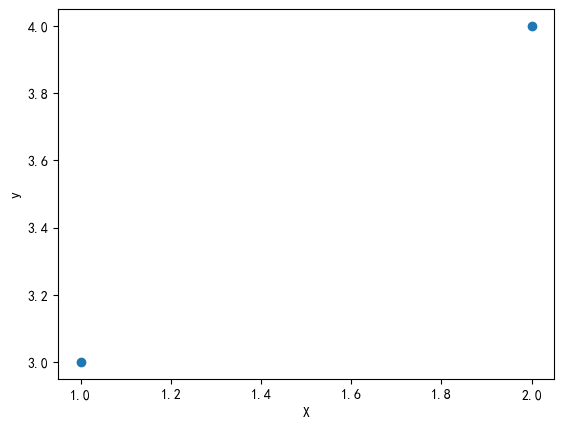

In [18]:
# 使用scikit-learn生成线性回归数据集
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']  # 解决Windows系统中文显示问题
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题

def generate_regression_data(bias: float=5.0) -> tuple[torch.Tensor, torch.Tensor, np.ndarray]:
    """
    偏置项bias后面画图要用到, 所以这里单独提取到形参
    生成线性回归数据集
    """
    # 生成数据集. 返回的都是numpy ndarray类型
    X, y, groundtruth_coef = make_regression(
        n_samples=100, # 样本数量
        n_features=1, # 特征数量
        # n_informative=1, # 有效特征数量 (真正对目标变量有影响的特征数量)
        n_targets=1, # 目标变量数量, 默认是1, 即单输出回归 wx+b = y标量
        bias=bias, # 偏置项(截距)
        noise=15, # 噪声
        random_state=123, # 随机种子
        coef=True # 是否返回真实的系数
    )

    # 将numpy数组封装为torch张量, 才能在PyTorch中计算
    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32).reshape(-1, 1) # 转为列向量, 方便计算
    return X_tensor, y_tensor, groundtruth_coef

- 生成数据集并绘制散点图

真实的系数: 33.86708459143266
X.shape: torch.Size([100, 1]), y.shape: torch.Size([100, 1])


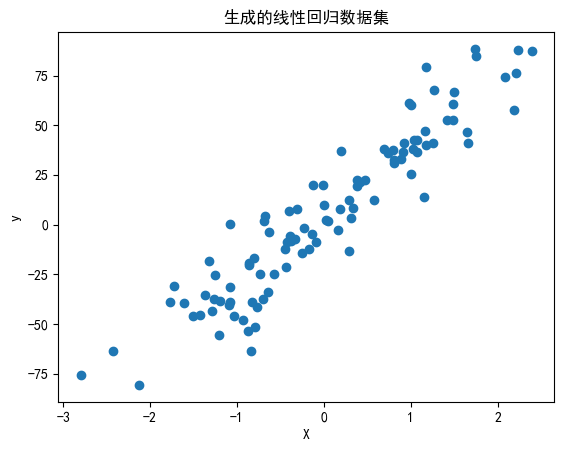

In [20]:
bias = 5.0
X, y, true_coef = generate_regression_data(bias)
print(f'真实的系数: {true_coef}')
print(f'X.shape: {X.shape}, y.shape: {y.shape}')
# 绘制数据集散点图
plt.scatter(X, y)
plt.xlabel('X')
plt.ylabel('y')
plt.title('生成的线性回归数据集')
plt.show()

- 创建数据集对象, 数据加载器对象, 线性回归模型, 损失函数和优化器

In [20]:
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim

# 构造数据集对象
dataset = TensorDataset(X, y)
# 构造数据加载器对象, 用于批量加载数据
# `batch_size`表示每个批次的样本数量, `shuffle`表示是否随机打乱数据集
batch_size = 16
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# 构造线性回归模型, 输入特征数量为1, 输出特征数量为1, 即: y = wx + b, 全都是标量
model = nn.Linear(in_features=1, out_features=1)

# 定义损失函数, 这里使用均方误差(MSE)损失函数
loss_fn = nn.MSELoss()
# 定义优化器, 这里使用随机梯度下降(SGD)优化器, 学习率为0.001
optimizer = optim.SGD(model.parameters(), lr=1e-3)

- 训练模型

In [ ]:
epochs = 1000 # 总的训练轮数
epoch_loss = [] # 用于记录每轮训练的平均损失值
batches = len(dataloader) # 每轮的批次数量 = 样本数 / 批次大小 = 100 / 16 = 6.25, 向上取整为7
print(f'batches = {batches}')
for epoch in range(epochs):
    total_loss = 0.0 # 记录当前这一轮(epoch)训练的总损失值
    # 📌📌数据加载器会自动将数据集划分为多个批次, 每个批次的样本数量<=batch_size
    for X_batch, y_batch in dataloader:
        # X_batch, y_batch的形状为[batch_size, 特征数量=1]
        # 前向传播, 计算预测值
        y_pred = model(X_batch)
        # 计算损失函数值
        loss = loss_fn(y_pred, y_batch)
        total_loss += loss.item() # 加上当前批次(batch)的平均损失值
        # 梯度清零
        optimizer.zero_grad()
        # 反向传播, 计算梯度
        loss.backward()
        # 更新参数
        optimizer.step()
    epoch_loss.append(total_loss / batches) # 计算当前轮训练的平均损失值
    if epoch % 10 == 0:
        print(f'第{epoch}轮训练 | loss: {epoch_loss[-1]}')

print('=' * 30)
print(f'训练完后的模型参数: w: {model.weight.detach()}, b: {model.bias.detach()}')
print(f'真实的系数: {true_coef}')

batches = 7
第0轮训练 | loss: 1591.6303972516741
第10轮训练 | loss: 1231.0733380998884
第20轮训练 | loss: 807.2253810337612
第30轮训练 | loss: 639.2647966657366
第40轮训练 | loss: 619.7319902692523
第50轮训练 | loss: 461.5036926269531
第60轮训练 | loss: 371.130124773298
第70轮训练 | loss: 351.96214076450894
第80轮训练 | loss: 270.0023847307478
第90轮训练 | loss: 232.85817773001534
第100轮训练 | loss: 232.67206464494978
第110轮训练 | loss: 217.54302978515625
第120轮训练 | loss: 197.58073016575403
第130轮训练 | loss: 207.04593767438615
第140轮训练 | loss: 205.4922147478376
第150轮训练 | loss: 195.17604391915458
第160轮训练 | loss: 198.37239946637834
第170轮训练 | loss: 214.14554377964564
第180轮训练 | loss: 194.7485634940011
第190轮训练 | loss: 249.4974648611886
第200轮训练 | loss: 229.36818150111608
第210轮训练 | loss: 181.54470934186662
第220轮训练 | loss: 199.6602739606585
第230轮训练 | loss: 205.97071184430803
第240轮训练 | loss: 234.0380859375
第250轮训练 | loss: 201.74488721575057
第260轮训练 | loss: 189.72495596749442
第270轮训练 | loss: 226.3779013497489
第280轮训练 | loss: 195.76921844482422


- 绘制训练损失曲线

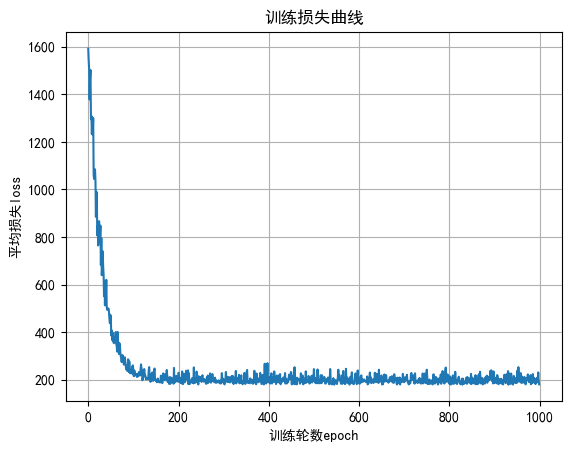

In [22]:
plt.plot(range(epochs), epoch_loss)
plt.title('训练损失曲线')
plt.xlabel('训练轮数epoch')
plt.ylabel('平均损失loss')
plt.grid()
plt.show()

- 绘制模型拟合直线

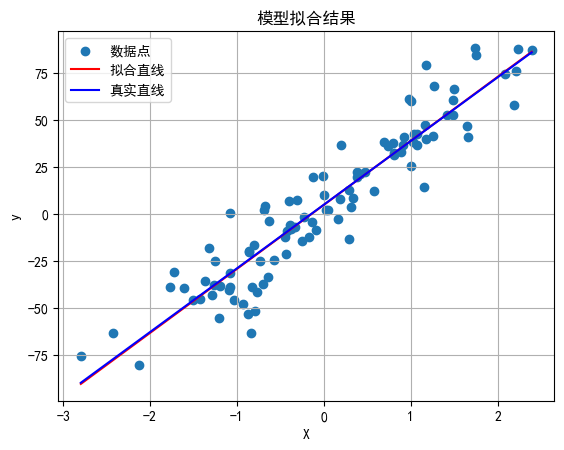

In [23]:
# 绘制原始数据点
plt.scatter(X, y, label='数据点')
# 绘制模型拟合直线
x_line = torch.linspace(X.min().item(), X.max().item(), 1000)
model.eval() # 设置模型为评估模式, 关闭dropout和batchnorm等层的训练行为
with torch.no_grad(): # 在不计算梯度的情况下进行前向传播
    y_line = model(x_line.reshape(-1, 1))
y_true = torch.tensor(true_coef) * x_line + bias
plt.plot(x_line, y_line.detach(), color='red', label='拟合直线')
plt.plot(x_line, y_true.detach(), color='blue', label='真实直线')
plt.xlabel('X')
plt.ylabel('y')
plt.title('模型拟合结果')
plt.legend()
plt.grid()
plt.show()